<a href="https://colab.research.google.com/github/WAHABU14/COU07506-labs/blob/main/COU07506_Week01_240242456127.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506: Digital Signal Processing
## Week 1 — Lab 0: Setting Up the DSP Laboratory
* **Name:** WAHABU R NASSORO
* **Registration Number:** 240242456127
* **Class Group:** BEng24COE
* **Date:** 23 November 2026


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)
print("Setup successful! Ready for DSP Lab 0.")

Setup successful! Ready for DSP Lab 0.


In [33]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Pre-lab question
### Device used today that contain DSP and their respective signals
* **Smartphone**: Process digital speech/audio signals during phone calls and voice recordings(noise suppression, compression).
* **Wi-Fi router**: Process modulated radio frequency (RF) communication signals to encode and decode internet data packets.
* **Smartwatch/Fitness tracker**: Process optical photoplethysmogram(PPG) or accelerometer to filter out motion artifacts and calculate heart rate or step count.

### Task 1.1 - my first notebook

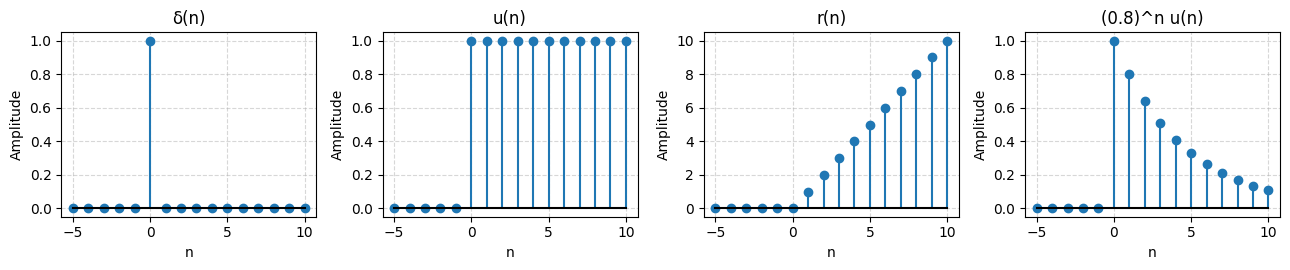

In [34]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = (0.8**n) * step              # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Task 1.2 - change the parameters

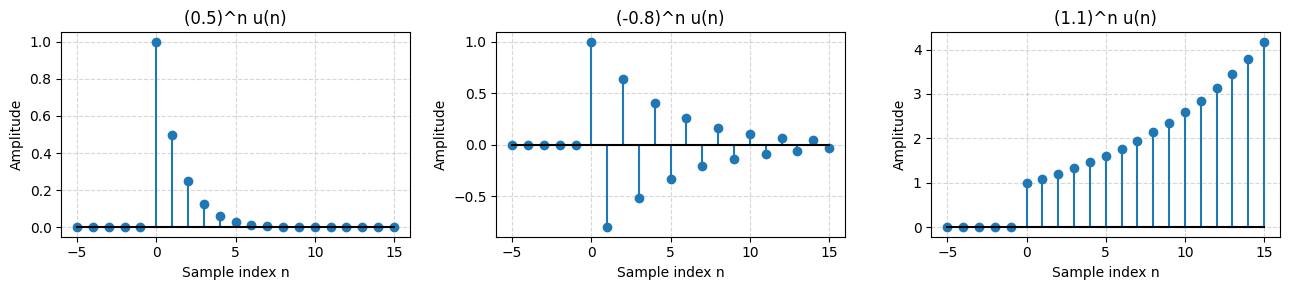

In [35]:
# Part 1: Real exponentials (a)^n u(n) for different values of a
n = np.arange(-5, 16)
u = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a**n) * u
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


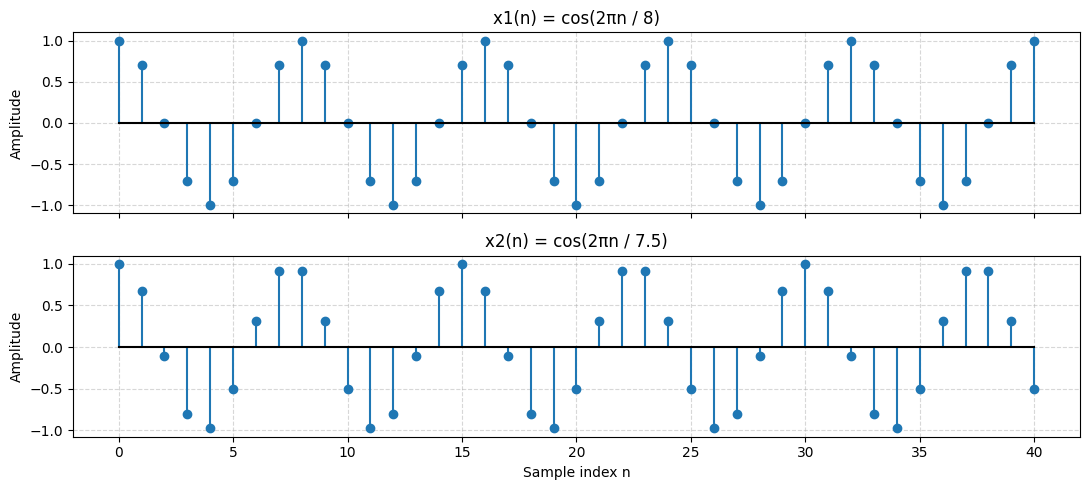

In [36]:
# Part 2: Comparing discrete-time sinusoids for 0 <= n <= 40
n_sin = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n_sin / 8)
x2 = np.cos(2 * np.pi * n_sin / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

# Top plot -> axes[0]
axes[0].stem(n_sin, x1, basefmt="k-")
axes[0].set_title("x1(n) = cos(2πn / 8)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Bottom plot -> axes[1]
axes[1].stem(n_sin, x2, basefmt="k-")
axes[1].set_title("x2(n) = cos(2πn / 7.5)")
axes[1].set_xlabel("Sample index n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


Which one repeats exactly?

Answer: cos(2$\pi$n/8)repeats its exact sample pattern every 8 samples(completing 5 exact cycles over $0 \le n \le40$), since the period N = 8 is already an integer, hence every cycle hits exact same sample amplitudes(1,0.707,0,-0.707,-1,...)

### Task 1.3 - Working with audio

In [37]:
!ffmpeg -y -i "/content/drive/MyDrive/DSP_LABS/my_voice.wav" "/content/drive/MyDrive/DSP_LABS/my_voice_converted.wav"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

Loaded your voice recording successfully!
fs = 48000 Hz, duration = 5.08 s, samples = 243712


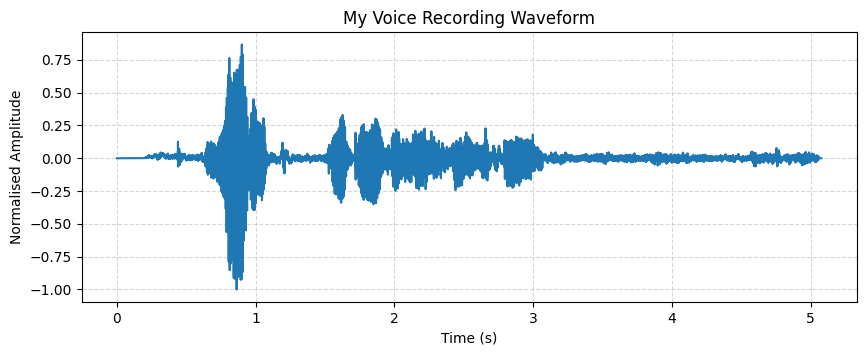

In [38]:
import os
from IPython.display import Audio

# Point to your Google Drive folder (or use "my_voice.wav" if uploaded directly to Colab)
fname = "/content/drive/MyDrive/DSP_LABS/my_voice_converted.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                  # Convert stereo (2 channels) -> mono (1 channel)
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))       # Normalise amplitude to [-1, 1]
    print("Loaded your voice recording successfully!")
else:                               # Fallback test signal if file isn't uploaded yet
    print("Audio file not found — running fallback 440 Hz test signal.")
    fs = 16000
    t_fb = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t_fb) * np.exp(-t_fb)

# Create time axis in seconds and print audio properties
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

# Plot the waveform
plt.figure(figsize=(10, 3.5))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Normalised Amplitude")
plt.title("My Voice Recording Waveform")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Display interactive audio player
Audio(x, rate=fs)


### Analysis questions


1.   What is the sampling rate of your phone recording?, How many numbers are needed to store one minute of it in mono?
* fs is 48000Hz
* from, samples = fs x 60s
* then samples = 48000Hz x 60 s
* therefore, number of samples needed is 2880000
2.   Why is a stem plot more appropiate than a continuous line for x(n)?
* A discreet-time signal x(n) is defined only at integer sample indices n. Values between integers do not exist(they are undefined, not zero). A stem plot accurately shows isolated data points at each integer n, whereas a continous line falsely implies the signal exists at non integer times.

3.   For $α$ = 1.1 the exponential grows.Which property of a system would such a signal violate if it were an impulse response (Unit 1 $ʂ$1.7)?
* It violates BIBO stability(Bounded-Input, Bounded-Output stability).For a discrete-time LTI system to be BIBO stable, its impulse response must be absolutely summable. Because h(n) = (1.1^n)u(n) grows toward infinity as n $→$ $∞$, its sum diverges making the system unstable.